In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
import sys, os
sys.path.append(os.path.abspath("C:/Users/ayush/OneDrive/Desktop/new model"))
from analysis.analysis_src.basic_data_inspection import (DataInspector,DataTypesInspectionStrategy,SummaryStatisticsInspectionStrategy)
from analysis.analysis_src.univariate_analysis import UnivariateAnalyzer, NumericalUnivariateAnalysis, CategoricalUnivariateAnalysis
from analysis.analysis_src.bivariate_analysis import (BivariateAnalyzer,NumericalVsNumericalStrategy,CategoricalVsNumericalStrategy)
from analysis.analysis_src.multivariate_analysis import SimpleMultivariateAnalysis
from analysis.analysis_src.missing_values_analysis import SimpleMissingValuesAnalysis

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

In [2]:
data_path=r"C:\Users\ayush\OneDrive\Desktop\new model\data\raw\house_price.csv"
df=pd.read_csv(data_path)
print("Data Loaded Successfully")

Data Loaded Successfully


In [3]:
data_inspector=DataInspector(DataTypesInspectionStrategy())
data_inspector.execute_inspection(df)


2025-09-10 13:25:18,357 - INFO - Executing data inspection strategy
2025-09-10 13:25:18,359 - INFO - Inspecting data types


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21609 entries, 0 to 21608
Data columns (total 21 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   ID                                         21609 non-null  int64  
 1   Date House was Sold                        21609 non-null  object 
 2   Sale Price                                 21609 non-null  float64
 3   No of Bedrooms                             21609 non-null  int64  
 4   No of Bathrooms                            21609 non-null  float64
 5   Flat Area (in Sqft)                        21609 non-null  float64
 6   Lot Area (in Sqft)                         21609 non-null  float64
 7   No of Floors                               21609 non-null  float64
 8   Waterfront View                            21609 non-null  object 
 9   No of Times Visited                        2124 non-null   object 
 10  Condition of the House

In [4]:
data_inspector.set_strategy(SummaryStatisticsInspectionStrategy())
data_inspector.execute_inspection(df)

2025-09-10 13:25:18,385 - INFO - Switching data inspection strategy
2025-09-10 13:25:18,386 - INFO - Executing data inspection strategy
2025-09-10 13:25:18,387 - INFO - Inspecting summary statistics



 summary statics (numerical features):
                 ID    Sale Price  No of Bedrooms  No of Bathrooms  \
count  2.160900e+04  2.160900e+04    21609.000000     21609.000000   
mean   4.580686e+09  5.116186e+05        3.370771         2.114709   
std    2.876653e+09  2.500620e+05        0.929916         0.770097   
min    1.000102e+06  7.500000e+04        0.000000         0.000000   
25%    2.123049e+09  3.219500e+05        3.000000         1.750000   
50%    3.904931e+09  4.500000e+05        3.000000         2.250000   
75%    7.308900e+09  6.450000e+05        4.000000         2.500000   
max    9.900000e+09  1.129575e+06       33.000000         8.000000   

       Flat Area (in Sqft)  Lot Area (in Sqft)  No of Floors  Overall Grade  \
count         21609.000000        2.160900e+04  21609.000000   21609.000000   
mean           2079.872553        1.510641e+04      1.494215       7.623490   
std             918.347816        4.142353e+04      0.539909       1.105519   
min          

,Missing Values,Percentage
No of Times Visited,19485,90.17


2025-09-10 13:27:08,294 - INFO - Identifying missing values...


Missing Values Count by Column:
No of Times Visited    19485
dtype: int64

Visualizing Missing Values...


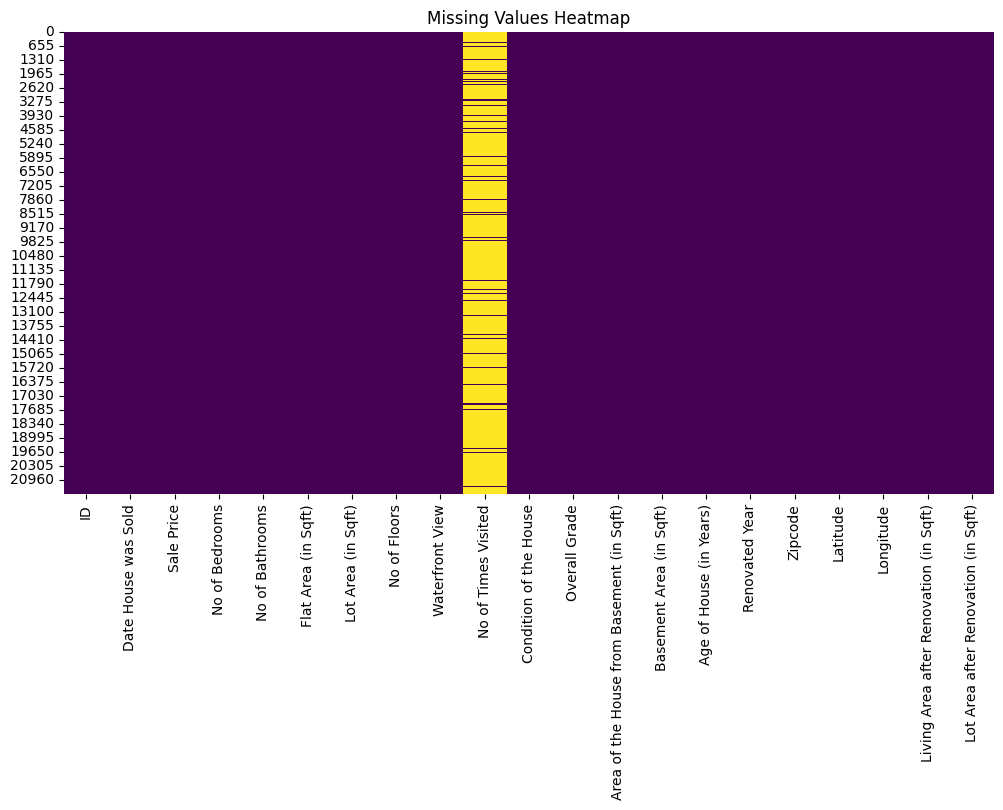

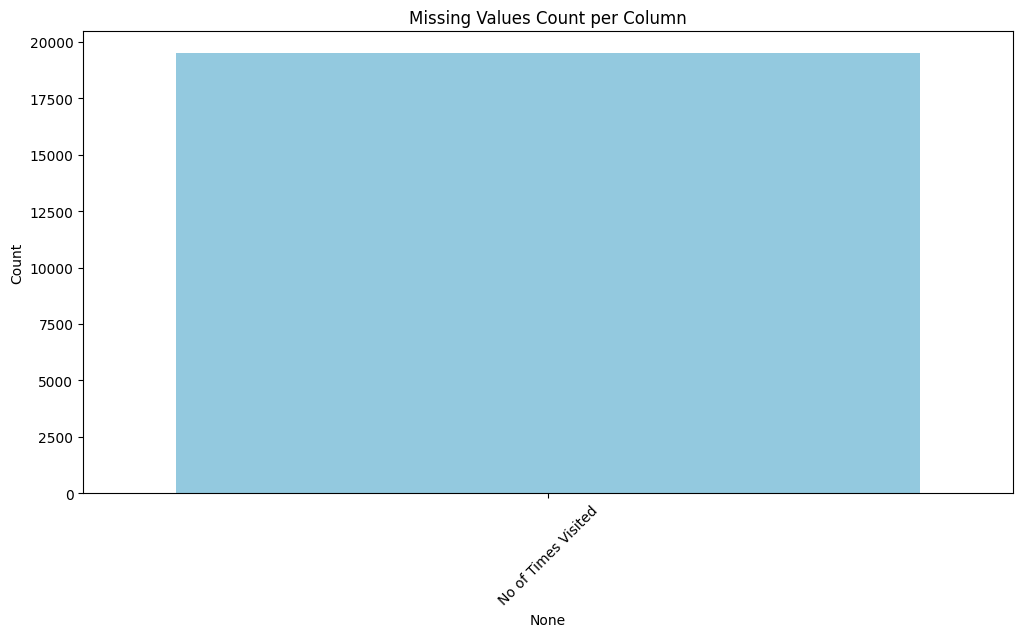

In [8]:
missing_values_analyzer = SimpleMissingValuesAnalysis()
missing_summary = missing_values_analyzer.analyze(df)
missing_summary


2025-09-10 16:16:24,673 - INFO - executing univariate analysis strategy


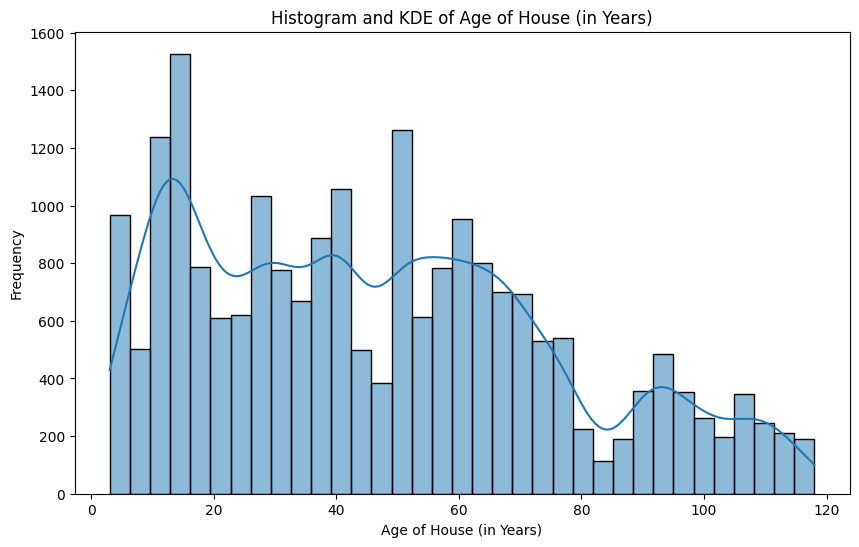

2025-09-10 16:16:25,065 - INFO - analyzed numerical feature: Age of House (in Years)


In [10]:
Univariate_Analyzer=UnivariateAnalyzer(NumericalUnivariateAnalysis())
Univariate_Analyzer.execute_analysis(df,"Age of House (in Years)")

2025-09-10 16:17:23,464 - INFO - switching univariate analysis strategy
2025-09-10 16:17:23,466 - INFO - executing univariate analysis strategy


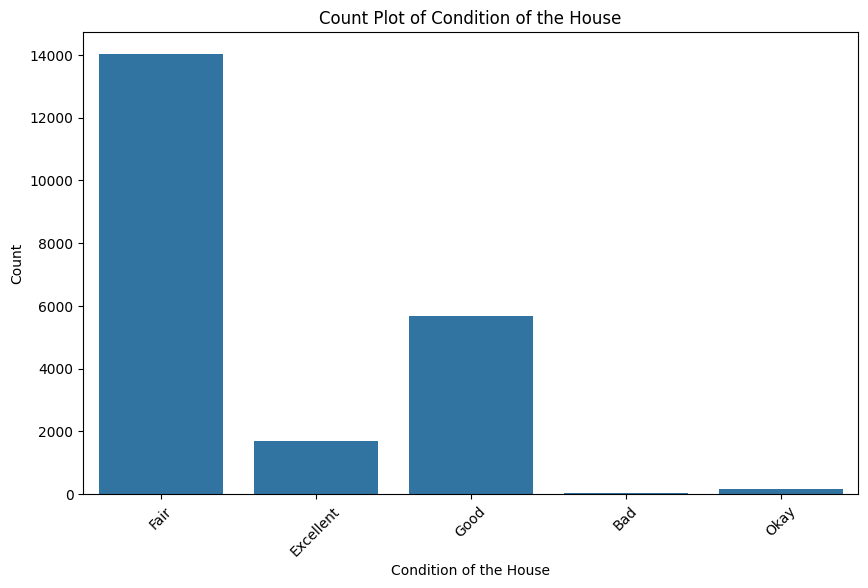

2025-09-10 16:17:23,682 - INFO - analyzed categorical feature: Condition of the House


In [12]:
Univariate_Analyzer.set_strategy(CategoricalUnivariateAnalysis())
Univariate_Analyzer.execute_analysis(df,"Condition of the House")

2025-09-10 16:18:55,207 - INFO - Executing bivariate analysis strategy
2025-09-10 16:18:55,209 - INFO - Analyzing numerical vs numerical: Flat Area (in Sqft) vs Sale Price


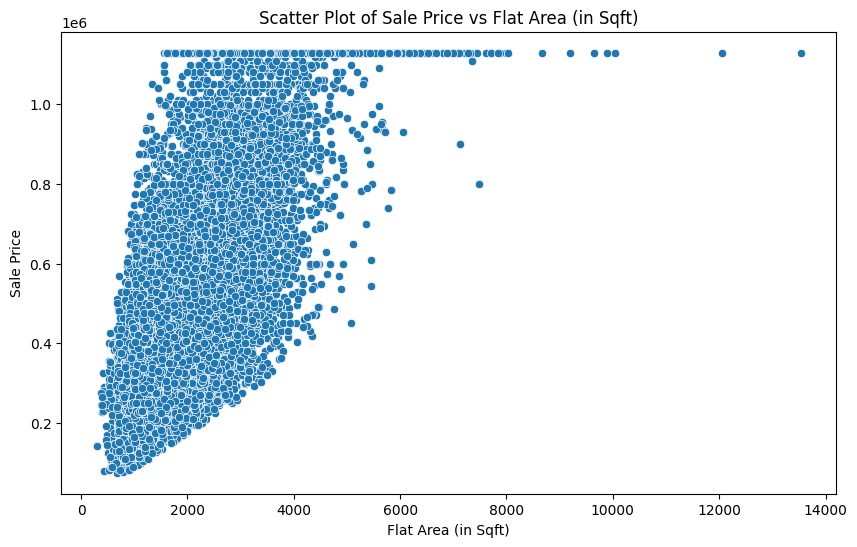

In [15]:
bivariate_analyzer = BivariateAnalyzer(NumericalVsNumericalStrategy())
bivariate_analyzer.execute_analysis(df, "Flat Area (in Sqft)", "Sale Price")

2025-09-10 16:19:54,874 - INFO - Switching bivariate analysis strategy
2025-09-10 16:19:54,877 - INFO - Executing bivariate analysis strategy
2025-09-10 16:19:54,878 - INFO - Analyzing categorical vs numerical: Condition of the House vs Sale Price


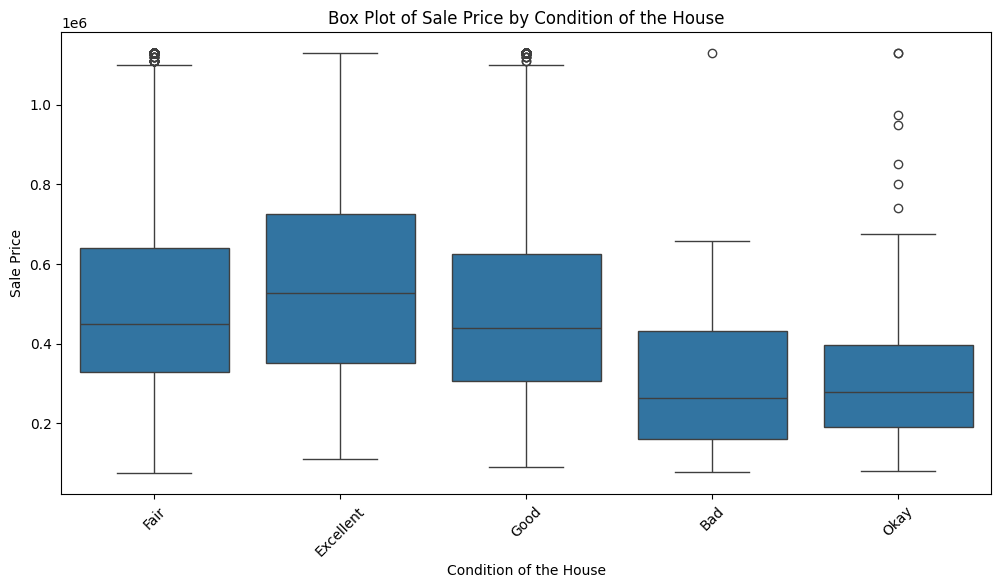

In [16]:
bivariate_analyzer.set_strategy(CategoricalVsNumericalStrategy())
bivariate_analyzer.execute_analysis(df, "Condition of the House", "Sale Price")

2025-09-10 16:22:21,607 - INFO - generating correlation heatmap


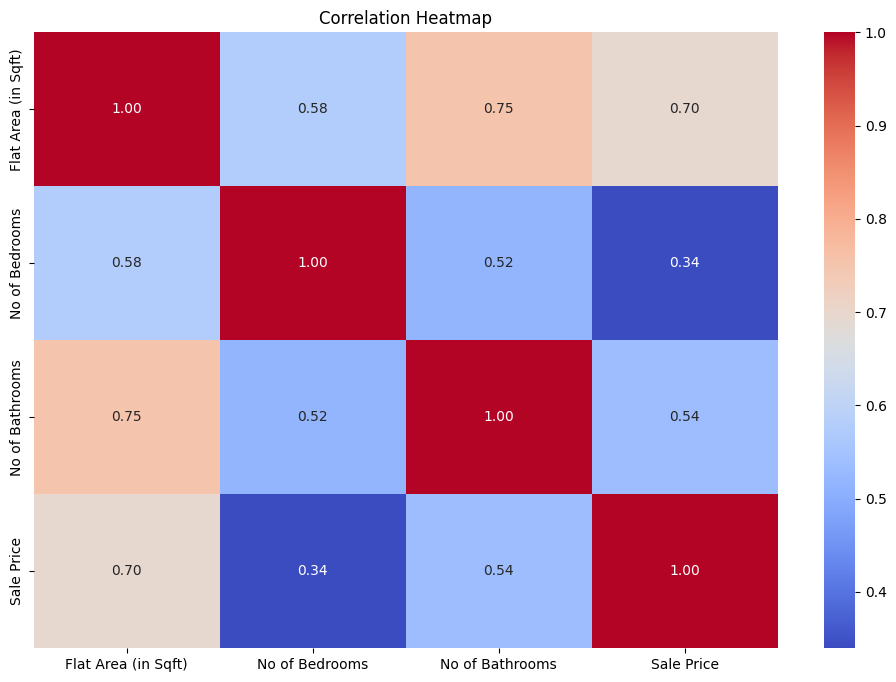

2025-09-10 16:22:21,808 - INFO - generating pairplot


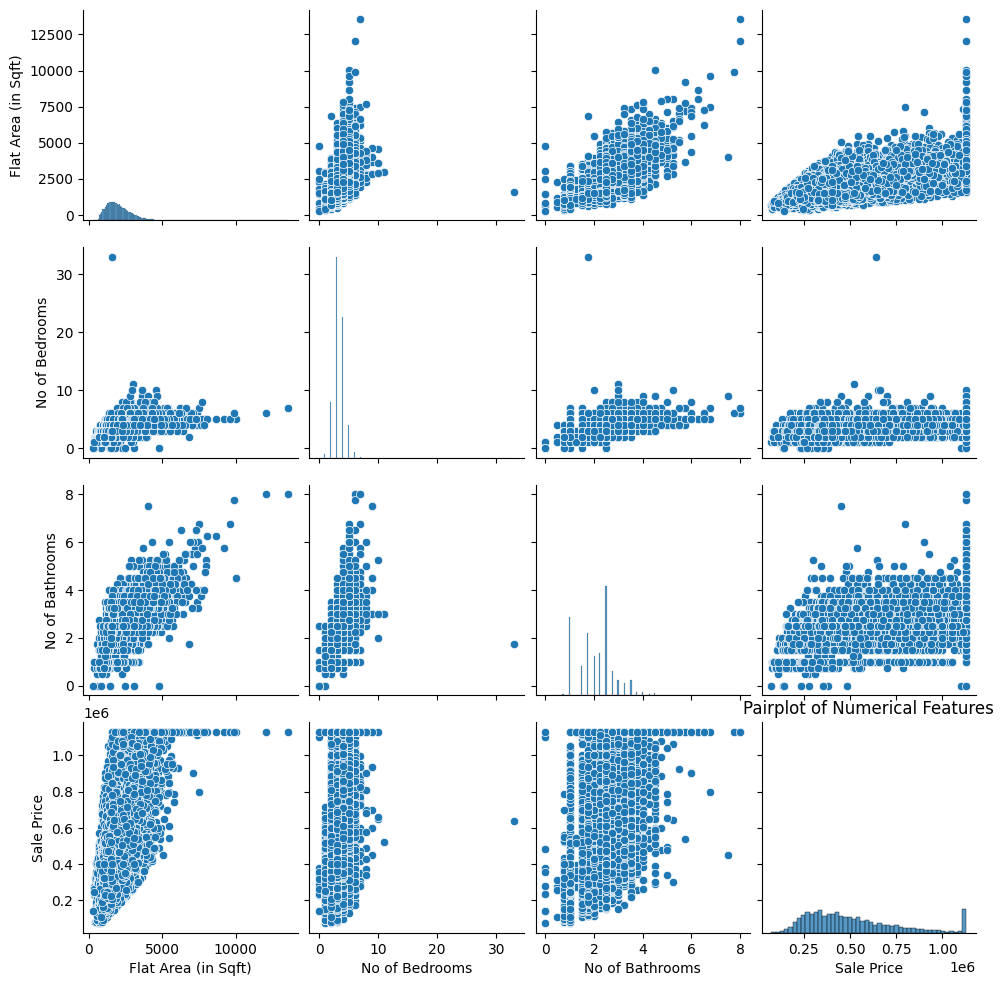

In [19]:
multivariate_analyzer=SimpleMultivariateAnalysis()
selected_features=df[["Flat Area (in Sqft)","No of Bedrooms","No of Bathrooms","Sale Price"
                      ]]
multivariate_analyzer.analyze(selected_features)